# temperature와 샘플링

**이 노트북에서 할 일**

1. 교재에서 정한 후보 점수 세 개를 temperature로 나눠 확률로 바꾸고, top_p 0.9로 남는 후보 수를 셉니다.
2. 같은 요청을 temperature 0.3과 1.0에서 시드 다섯 개로 실행하고, 답의 가짓수와 끝 표시를 셉니다.
3. 같은 시드로 한 번 더 실행해 답이 같은지 보고, 뽑기를 켠 채 temperature 0.0을 넣어 봅니다.

**준비물** — API 키는 필요 없습니다. 인터넷 서비스의 모델을 부르지 않고, 내 컴퓨터에서 작은 언어 모델을 실행합니다.
그래서 비용은 들지 않습니다. 모델이 답을 만드는 계산은 모두 16번 합니다.

실행 시간은 1분 안팎입니다. 모델 파일은 03~05절과 같은 약 1GB(954MiB)이고, 캐시에 없으면 Hugging Face 사이트에서 내려받습니다.
노트북과 같은 계산을 스크립트로 실행했을 때 Python이 쓴 메모리는 최대 약 3.2GB였습니다.

**기준 버전** — 실습 폴더에 고정한 transformers 4.56.2와 torch 2.8.0을 씁니다. 함께 고정한 NumPy는 2.3.3입니다.
모델은 `Qwen/Qwen2.5-0.5B-Instruct`이고, 판 번호(revision)를 `7ae557604adf67be50417f59c2c2f167def9a775`로 고정해 받습니다.

교재 출력은 Linux(aarch64)의 Python 3.12.13과 CPU용 torch(2.8.0+cpu)로 만들었습니다.
시드를 같게 줘도 버전이나 기기가 바뀌면 답이 달라질 수 있습니다. 확인한 범위는 정리 셀 위 10절에 적었습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 01절과 같은 `.venv` 커널을 고른 뒤 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

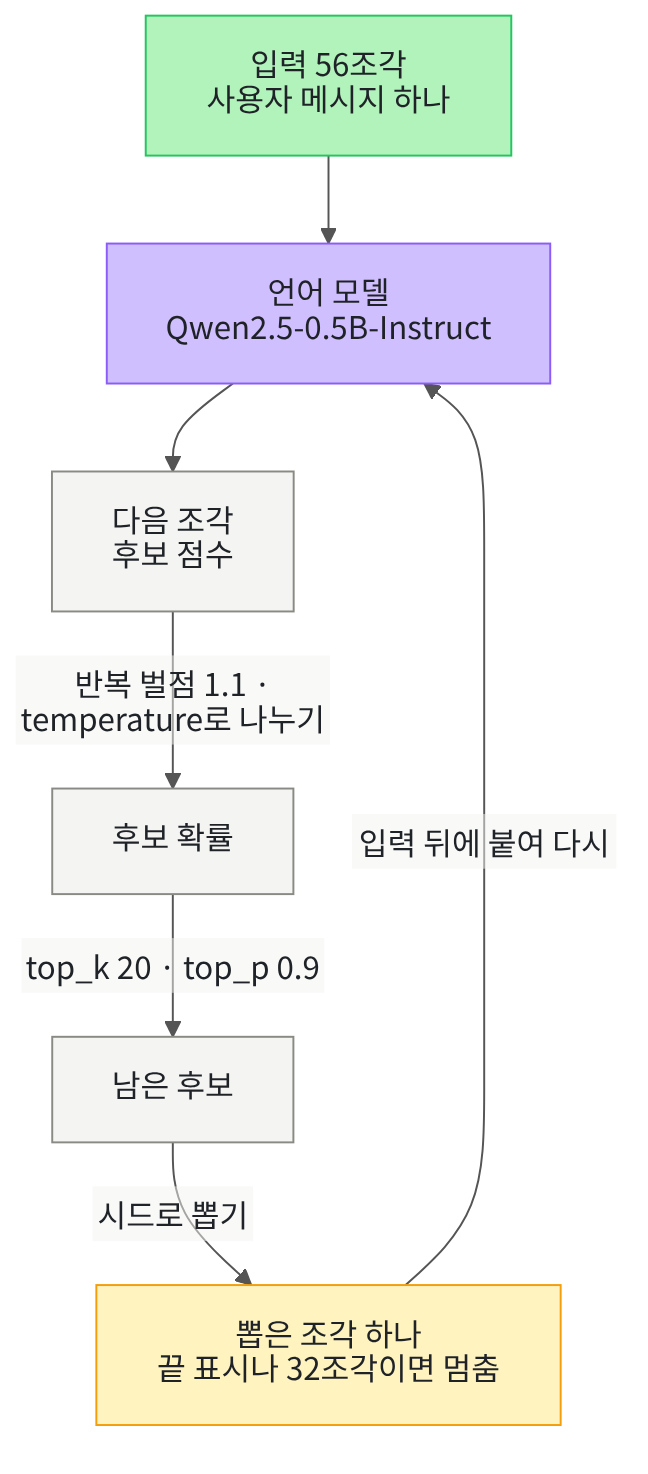

위에서 아래로 읽습니다. 초록 상자는 노트북에서 만든 입력이고, 보라 상자는 실행한 언어 모델입니다.
회색 상자는 메서드 `generate()` 안에서 계산되어 화면에 나오지 않는 값이고, 노란 상자는 출력으로 확인하는 조각입니다.
뽑은 조각을 입력 뒤에 붙여 다시 모델에 넣는 일을, 끝 표시가 나오거나 32조각이 될 때까지 되풀이합니다.

## 1. 준비

이 절은 파일을 읽거나 만들지 않습니다. 준비 셀에서는 계산에 쓸 모듈과 패키지를 불러오고 버전을 확인합니다.

패키지 NumPy는 02·03절에서 벡터 계산에 쓴 패키지입니다.
함수 `set_seed()`는 이 절에서 처음 쓰는 transformers 함수이고, 뜻은 6절에서 풉니다.
패키지 torch는 03절에서 본 텐서를 계산하는 패키지입니다. 뽑기에 쓰는 난수도 torch가 만들어서 버전을 함께 출력합니다.

함수 `warnings.filterwarnings()` 줄은 01절처럼 진행 표시 위젯 경고 한 줄을 끕니다.
함수 `transformers.logging.set_verbosity_error()`는 04절처럼, 오류가 아닌 생성 안내를 화면에 내지 않게 합니다.

앞에서 배운 함수는 `llm_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 03절 `softmax()`와 05절 `ask_model()`을 가져옵니다. 도구 파일의 `ask_model()`은 05절과 계산이 같고, 모델·토큰화기·출력 몫을 인자로 받습니다.

In [1]:
# NumPy와 transformers·torch 패키지, 앞 절 함수를 불러오고 버전을 확인합니다
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import torch
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
# 03절 소프트맥스와 05절 답 받기 함수를 도구 파일에서 가져옵니다
from llm_tools import ask_model, softmax

# 생성 셀의 안내(오류 아님)를 화면에 내지 않습니다
transformers.logging.set_verbosity_error()
print("transformers 버전:", transformers.__version__)
print("torch 버전:", torch.__version__)

transformers 버전: 4.56.2
torch 버전: 2.8.0+cpu


**결과 읽기** — 출력 줄은 `transformers 버전: 4.56.2`와 `torch 버전: 2.8.0+cpu`입니다. 준비물에 적은 기준 버전과 같습니다.

torch 버전 끝의 `+cpu`는 GPU 없이 CPU로 계산하는 판이라는 표시입니다.

## 2. 후보 점수를 확률로 — temperature로 나누기

모델은 다음 조각을 정하기 전에 후보 조각마다 점수를 매깁니다. 이 점수를 로짓(logit)이라고 부릅니다.
03절의 소프트맥스로 점수를 바꾸면 모두 0보다 크고 합이 1인 확률이 됩니다.
04·05절의 인자 `do_sample=False`는 반복 벌점(4절에서 봄)을 적용한 점수에서 가장 큰 후보를 고르는 설정이었습니다.

샘플링(sampling)은 가장 큰 후보만 고르지 않고, 확률대로 후보 하나를 뽑는 방식입니다.
후보마다 확률만큼 제비를 넣은 통에서 한 장을 뽑는 것과 비슷합니다. 확률 0.7인 후보는 열 번 뽑으면 일곱 번쯤 나옵니다.

소프트맥스에 넣기 전에 점수를 나누는 값이 temperature입니다. 1보다 작은 값으로 나누면 점수 차이가 커지고, 1보다 큰 값으로 나누면 차이가 줄어듭니다.
점수 차이가 커지면 큰 후보의 확률이 더 커집니다. 소프트맥스는 준비 셀에서 가져온 03절 함수 `softmax()`를 씁니다.

점수는 03절처럼 NumPy 배열로 만듭니다. 배열을 수 하나로 나누면 값마다 나눈 새 배열이 됩니다.
함수 `np.round(배열, 자릿수)`는 값마다 반올림하고, 메서드 `tolist()`는 배열을 Python 목록으로 바꿉니다.

교재에서 정한 후보 점수 `[2.0, 1.0, 0.0]`으로 두 함수를 부릅니다. 실제 모델의 점수가 아니라 계산을 보려고 정한 숫자입니다.
나눌 temperature 값은 0.3, 1.0, 2.0 세 가지입니다. 0.3과 1.0은 7절에서 실제 모델에 넣을 값입니다.

실행 전에 예상합니다. 0.3으로 나누면 점수가 6.67, 3.33, 0.0이 되어 첫 후보의 확률이 0.9를 넘을 것입니다.
2.0으로 나누면 점수가 1.0, 0.5, 0.0으로 좁혀져 세 확률이 서로 가까워질 것입니다.

In [2]:
# 교재 점수 세 개를 temperature 0.3, 1.0, 2.0으로 나눈 뒤 확률로 바꿔 봅니다
candidate_scores = np.array([2.0, 1.0, 0.0])
print("temperature | 나눈 점수 | 확률")
for temperature in [0.3, 1.0, 2.0]:
    # 배열을 temperature로 나누면 점수마다 나눈 새 배열이 됩니다
    divided = candidate_scores / temperature
    probabilities = softmax(divided)
    # 표로 보기 좋게 나눈 점수는 둘째 자리, 확률은 넷째 자리까지 반올림해 목록으로 바꿉니다
    rounded_scores = np.round(divided, 2).tolist()
    rounded_probabilities = np.round(probabilities, 4).tolist()
    print(temperature, "|", rounded_scores, "|", rounded_probabilities)

temperature | 나눈 점수 | 확률
0.3 | [6.67, 3.33, 0.0] | [0.9644, 0.0344, 0.0012]
1.0 | [2.0, 1.0, 0.0] | [0.6652, 0.2447, 0.09]
2.0 | [1.0, 0.5, 0.0] | [0.5065, 0.3072, 0.1863]


**결과 읽기** — 라벨 줄 아래 첫 줄은 `0.3 | [6.67, 3.33, 0.0] | [0.9644, 0.0344, 0.0012]`입니다. 둘째 줄은 `1.0 | [2.0, 1.0, 0.0] | [0.6652, 0.2447, 0.09]`입니다.

셋째 줄은 `2.0 | [1.0, 0.5, 0.0] | [0.5065, 0.3072, 0.1863]`입니다. 예상대로 temperature가 작을수록 첫 후보에 확률이 몰렸습니다.
세 줄 모두 가장 큰 후보는 첫 후보입니다. 나누는 값을 바꿔도 후보의 순서는 그대로이고, 후보 사이의 확률 차이만 바뀝니다.

## 3. top_p — 확률이 큰 후보만 남기기

설정 top_p는 확률이 큰 후보부터 차례로 더해, 합이 정한 값에 닿을 때까지의 후보만 남깁니다. 남은 후보 안에서만 뽑습니다.
투표에서 1등부터 득표율을 더해 90%에 닿을 때까지의 후보만 결선에 올리는 것과 비슷합니다.

아래 함수는 확률 목록을 앞에서부터 더하며 남는 후보 수를 셉니다. 확률이 큰 순서로 놓인 목록을 넣어야 맞습니다.
2절의 교재 확률은 이미 큰 순서입니다. 이 셀은 함수를 정의만 합니다.

In [3]:
# 확률이 큰 순서의 목록을 앞에서부터 더해, 합이 기준에 닿을 때까지 남는 후보 수를 반환하는 함수를 정의합니다
def count_top_p(probabilities, cutoff):
    total = 0
    kept_count = 0
    for probability in probabilities:
        kept_count = kept_count + 1
        total = total + probability
        # 더한 확률이 기준 이상이 되면 이 후보까지 남기고 멈춥니다
        if total >= cutoff:
            break
    return kept_count

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

기준은 7절에서 실제 모델에 넣을 값과 같은 0.9로 정하고, 이름 `top_p`에 담습니다. 2절의 세 temperature로 남는 후보 수를 셉니다.
실행 전에 예상합니다. 0.3에서는 첫 후보 확률 0.9644가 혼자 0.9를 넘으니 1개가 남을 것입니다. 2.0에서는 두 후보를 더해도 0.8137이라 3개가 남을 것입니다.

In [4]:
# top_p 0.9로 정하고, 세 temperature에서 남는 후보 수를 셉니다
top_p = 0.9
print("temperature | top_p 0.9로 남는 후보 수")
for temperature in [0.3, 1.0, 2.0]:
    probabilities = softmax(candidate_scores / temperature)
    kept_count = count_top_p(probabilities, top_p)
    print(temperature, "|", kept_count)

temperature | top_p 0.9로 남는 후보 수
0.3 | 1
1.0 | 2
2.0 | 3


**결과 읽기** — 라벨 줄 아래 세 줄은 `0.3 | 1`, `1.0 | 2`, `2.0 | 3`입니다. 예상과 같습니다.

1.0에서는 0.6652와 0.2447을 더한 0.9099가 0.9 이상이라 두 후보에서 멈췄습니다.
이 교재 점수에서 temperature 0.3과 top_p 0.9를 함께 쓰면 후보가 하나만 남습니다. 그러면 뽑아도 늘 같은 후보가 나옵니다.
실제 모델의 점수는 이 교재 점수와 다르므로, 같은 일이 일어나는지는 7절 답으로 확인합니다.

## 4. 모델과 기본 생성 설정

모델은 03~05절과 같은 Qwen2.5-0.5B-Instruct이고, 같은 판 번호로 받습니다.
모델 파일에는 답을 만들 때 쓸 기본값을 적은 생성 설정(generation config)도 들어 있습니다. 모델 객체의 속성 `generation_config`로 읽습니다.

메서드 `generate()`에 인자로 넘긴 값은 그 호출에서 기본값보다 먼저 쓰입니다. 넘기지 않은 값은 기본값이 그대로 쓰입니다.
그래서 이번에 넘기지 않을 값이 무엇인지 먼저 봅니다. 실행 전에 예상합니다. 04절 안내 경고가 샘플링 설정 값을 말했으니, 기본값에 temperature가 있을 것입니다.

In [5]:
# 03~05절과 같은 언어 모델과 토큰화기를 받고, 모델 파일에 든 기본 생성 설정을 봅니다
model_name = "Qwen/Qwen2.5-0.5B-Instruct"
model_revision = "7ae557604adf67be50417f59c2c2f167def9a775"
tokenizer = AutoTokenizer.from_pretrained(model_name, revision=model_revision)
model = AutoModelForCausalLM.from_pretrained(model_name, revision=model_revision)
# 모델 파일의 기본 생성 설정 가운데 뽑기와 관련된 값만 출력합니다
settings = model.generation_config
print("기본 do_sample:", settings.do_sample)
print("기본 temperature:", settings.temperature)
print("기본 top_p:", settings.top_p)
print("기본 top_k:", settings.top_k)
print("기본 repetition_penalty:", settings.repetition_penalty)

기본 do_sample: True
기본 temperature: 0.7
기본 top_p: 0.8
기본 top_k: 20
기본 repetition_penalty: 1.1


**결과 읽기** — 출력 줄은 `기본 do_sample: True`, `기본 temperature: 0.7`, `기본 top_p: 0.8`, `기본 top_k: 20`, `기본 repetition_penalty: 1.1`입니다.

예상대로 기본값에 temperature가 있고, 뽑기도 켜져 있습니다. 04·05절은 `do_sample=False`를 넘겨서 뽑기를 껐습니다.
이 절은 do_sample, temperature, top_p 세 값을 넘깁니다. 나머지 top_k와 repetition_penalty는 넘기지 않습니다.

기본값 top_k 20은 점수가 큰 후보 20개만 남기는 값입니다. 기본값 repetition_penalty 1.1은 입력과 답에 이미 나온 조각의 점수를 조금 낮춥니다.
반복 벌점 1.1은 이 절의 모든 호출에 쓰입니다. 기본값 top_k 20은 뽑기를 켠 호출에서만 쓰입니다. 이 노트북의 출력은 2026-09-21에 이 모델과 판 번호로 실행한 결과입니다.

## 5. 입력과 뽑기를 끈 답

입력은 사용자 메시지 하나입니다. 05절 6절처럼 시스템 메시지가 없어서, 채팅 템플릿이 영어 기본 지시를 넣습니다.
요청은 행사 이름 하나를 짧게 지어 달라는 글입니다. 정답이 하나로 정해진 질문이 아니라서, 뽑기에 따라 답이 갈리는지 보기 좋습니다.

출력 몫은 05절처럼 32로 정합니다. 먼저 04·05절처럼 `do_sample=False`로 답을 한 번 받아, 뽑기를 켠 답과 비교할 기준으로 둡니다.
새 조각 수가 출력 몫에 닿기 전에 끝나면, 04절에서 본 끝 표시 `<|im_end|>`가 답 끝에 남습니다.

In [6]:
# 사용자 메시지 하나로 입력을 만들고, 출력 몫 32를 정해 입력 토큰 수를 셉니다
request_text = "오프라인 서점의 가을 행사 이름을 한국어 5어절 이내로 하나 제안하세요."
message_list = [
    {"role": "user", "content": request_text},
]
input_text = tokenizer.apply_chat_template(message_list, tokenize=False, add_generation_prompt=True)
input_ids = tokenizer.encode(input_text, return_tensors="pt")
input_length = len(input_ids[0])
output_budget = 32
print("입력 토큰 수:", input_length)
print("출력 몫:", output_budget)

입력 토큰 수: 56
출력 몫: 32


**결과 읽기** — 출력 줄은 `입력 토큰 수: 56`과 `출력 몫: 32`입니다.

영어 기본 지시가 들어간 입력이라, 요청 글만 셀 때보다 조각 수가 많습니다. 이 입력을 이 절의 모든 호출에서 그대로 씁니다.

다음 셀은 뽑기를 끈 설정으로 답을 받습니다. 준비 셀에서 가져온 05절 `ask_model()`에 모델, 토큰화기, 입력 글, 출력 몫을 넘깁니다.
실행 전에 예상합니다. 05절처럼 다시 실행해도 같은 답이 나올 것입니다.

In [7]:
# 04·05절처럼 뽑기를 끈 설정으로 답을 한 번 받아, 비교할 기준으로 둡니다
greedy_answer = ask_model(model, tokenizer, input_text, output_budget)
print("뽑기를 끈 답:", greedy_answer)

뽑기를 끈 답: "가을의 푸른 시원ness: 오프라인 서점의 전통과 새로운 활동들"<|im_end|>


**결과 읽기** — 출력 줄은 `뽑기를 끈 답: "가을의 푸른 시원ness: 오프라인 서점의 전통과 새로운 활동들"<|im_end|>`입니다.

따옴표 안에 이름 하나를 답했고, 끝 표시가 있어 출력 몫 안에서 끝났습니다. 영어 조각 `ness`가 섞인 것은 이 작은 모델의 답 그대로입니다.
이 셀을 다시 실행해도 같은 답이 나옵니다. 05절 7절에서 같은 입력은 같은 답을 낸다는 것을 확인했습니다.

## 6. 시드 — 뽑기의 시작점

컴퓨터의 뽑기는 난수(무작위로 보이는 수)로 합니다. 이 난수는 시작 번호에서 정해진 순서로 만들어집니다. 이 시작 번호를 시드(seed)라고 부릅니다.
번호마다 주사위 눈을 미리 적어 둔 목록과 비슷합니다. 같은 번호의 목록을 펴면 같은 순서로 눈이 나옵니다.

함수 `set_seed(번호)`는 Python·NumPy·torch의 난수 시작점을 한꺼번에 그 번호로 정합니다.
아래 함수는 호출마다 먼저 시드를 정합니다. 그다음 인자 `do_sample=True`로 뽑기를 켜고 temperature와 top_p를 넘깁니다.

인자 `temperature`와 `top_p`는 2·3절에서 교재 점수로 계산한 그 값입니다. 3절에서 정한 `top_p` 0.9를 모든 호출에 씁니다.
몸통의 나머지는 05절 `ask_model()`과 같은 모양입니다. 이 셀은 함수를 정의만 합니다.

In [8]:
# temperature와 시드를 받아, 뽑기를 켠 설정으로 만든 새 조각을 글로 바꿔 반환하는 함수를 정의합니다
def ask_with_sampling(temperature, seed):
    # 호출마다 시드를 먼저 정해, 같은 시드면 같은 순서의 난수로 뽑게 합니다
    set_seed(seed)
    output_ids = model.generate(
        input_ids=input_ids,
        max_new_tokens=output_budget,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
    )
    all_ids = output_ids[0].tolist()
    return tokenizer.decode(all_ids[input_length:len(all_ids)])

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

바꾸는 값은 temperature 하나입니다. 0.3과 1.0 두 가지에 같은 시드 다섯 개 11, 22, 33, 44, 55를 씁니다.
입력, 출력 몫, top_p, 기본 설정의 top_k와 repetition_penalty는 모든 호출에서 같습니다.

답은 temperature를 키로 한 딕셔너리에 목록으로 모읍니다. 답 안의 줄바꿈은 05절처럼 빈칸으로 바꿔 한 줄에 출력합니다.
실행 전에 예상합니다. 3절의 교재 점수처럼 0.3에서 후보가 하나만 남는다면, 0.3의 답 다섯 개는 5절 답과 같을 것입니다.

In [9]:
# temperature 0.3과 1.0에서 같은 시드 다섯 개로 답을 받아 모읍니다
temperatures = [0.3, 1.0]
seeds = [11, 22, 33, 44, 55]
answers_by_temperature = {}
print("temperature | 시드 | 답")
for temperature in temperatures:
    answer_list = []
    for seed in seeds:
        answer = ask_with_sampling(temperature, seed)
        answer_list.append(answer)
        print(temperature, "|", seed, "|", answer.replace("\n", " "))
    answers_by_temperature[temperature] = answer_list

temperature | 시드 | 답


0.3 | 11 | "열정과 풍부한 책: 오프라인 서점의 가을 행사를 맞이합니다."<|im_end|>


0.3 | 22 | 1. "열매와 함께: 가을의 풍경" 2. "오늘의 날씨: 가을의 봄


0.3 | 33 | "가을의 푸른 시선: 오프라인 서점의 봄행사"<|im_end|>


0.3 | 44 | "가을의 푸른 꽃들: 오프라인 서점의 전시회"<|im_end|>


...

1.0 | 11 | 죄송합니다, 저는 실시간 정보나 실제 위치에 맞는 인적 자원을 가지고 있지 않습니다. 하지만 저에게 직접 제공하는 정보를 주


1.0 | 22 | 1. "열린 시선" (Sunlit Eye) 2. "월드를 뚫고" (Might have Gone) 3.


1.0 | 33 | "온라인 어워서행 특별 판매"<|im_end|>


1.0 | 44 | 오프라인 서점의 가을 행사는 다음과 같은 내용을 다루고 있어요:  1. "열정 넘치는 가을


1.0 | 55 | 1. 겨울의 명상자와 함께 2. 따뜻한 책이 어우러진 잔잔함 3. 비록


**결과 읽기** — 라벨 줄 아래 앞 다섯 줄이 temperature 0.3입니다. 시드 11은 `"열정과 풍부한 책: 오프라인 서점의 가을 행사를 맞이합니다."<|im_end|>`이고, 시드 22는 `1. "열매와 함께: 가을의 풍경"`으로 시작하는 번호 목록입니다.

예상과 달리 0.3의 답 다섯 개는 모두 5절 답과 다르고, 서로도 다릅니다. 실제 모델의 후보 점수는 3절 교재 점수처럼 한 후보에 몰리지 않은 자리가 있었습니다.
시드 33과 55는 가을 행사를 물었는데 이름 끝에 `봄행사`를 붙였습니다.

뒤 다섯 줄은 temperature 1.0입니다. 시드 11은 `죄송합니다`로 시작해 이름을 내지 않았고, 시드 55는 `1. 겨울의 명상자와 함께`로 시작합니다.
1.0에서는 다섯 줄 가운데 네 줄이 끝 표시 없이 32조각에서 끊겼습니다.

## 7. 답 세기 — 가짓수, 끝 표시, 요청 낱말

6절 답을 temperature마다 세 가지로 셉니다. 첫째는 서로 다른 답의 수입니다.
Ch 2 03절의 집합 `set()`은 같은 값을 하나로 합치므로, 집합의 길이가 서로 다른 답의 수입니다.

둘째는 끝 표시가 있는 답의 수이고, 셋째는 요청 낱말 「가을」이 들어간 답의 수입니다. 둘 다 05절처럼 연산자 `in`으로 봅니다. 셋째 셈은 6절에서 `봄행사` 답을 본 뒤 더한 셈입니다.

세 값은 글자로만 센 것이라 이름이 좋은지는 알려 주지 않습니다. 실행 전에 예상합니다. 6절에서 본 대로 서로 다른 답은 두 temperature 모두 5개일 것입니다.

In [10]:
# temperature마다 서로 다른 답 수, 끝 표시가 있는 답 수, "가을"이 들어간 답 수를 셉니다
print("temperature | 서로 다른 답 | 끝 표시 있음 | 가을 들어감")
for temperature in temperatures:
    answer_list = answers_by_temperature[temperature]
    different_count = len(set(answer_list))
    finished_count = 0
    autumn_count = 0
    for answer in answer_list:
        if "<|im_end|>" in answer:
            finished_count = finished_count + 1
        if "가을" in answer:
            autumn_count = autumn_count + 1
    print(temperature, "|", different_count, "|", finished_count, "|", autumn_count)

temperature | 서로 다른 답 | 끝 표시 있음 | 가을 들어감
0.3 | 5 | 4 | 5
1.0 | 5 | 1 | 1


**결과 읽기** — 라벨 줄 아래 두 줄은 `0.3 | 5 | 4 | 5`와 `1.0 | 5 | 1 | 1`입니다.

서로 다른 답의 수는 두 temperature 모두 5개라, 이 셈으로는 차이가 보이지 않습니다. 0.3에서도 이미 다섯 번 모두 다른 답이 나왔기 때문입니다.
끝 표시와 「가을」 수는 1.0에서 적었습니다. 1.0의 답은 32조각 안에 끝나지 않거나 요청 낱말을 쓰지 않은 경우가 많았습니다.

다만 요청 하나에 시드 다섯 개로 본 결과입니다. 「가을」이 들어간 `봄행사` 답도 세었으므로, 이 수가 요청을 잘 따랐다는 뜻은 아닙니다.

## 8. 같은 시드로 한 번 더

6절 답이 시드로 정해진 것인지 확인합니다. 가장 답이 흩어진 temperature 1.0에서, 같은 시드 다섯 개로 한 번 더 실행합니다.
05절 7절처럼 조건 번호 `number`를 0부터 늘리며, 6절에 모아 둔 목록의 같은 자리 답과 글자까지 비교합니다.

실행 전에 예상합니다. 시드를 호출마다 같게 정했으니 다섯 개 모두 같은 답일 것입니다.

In [11]:
# temperature 1.0에서 같은 시드 다섯 개로 한 번 더 답을 받아, 6절의 답과 같은지 셉니다
first_answers = answers_by_temperature[1.0]
same_count = 0
number = 0
for seed in seeds:
    answer = ask_with_sampling(1.0, seed)
    # 같은 시드로 받은 6절의 답과 글자까지 같은지 비교합니다
    if answer == first_answers[number]:
        same_count = same_count + 1
    number = number + 1
print("같은 답 수:", same_count, "/", len(seeds))

같은 답 수: 5 / 5


**결과 읽기** — 출력 줄은 `같은 답 수: 5 / 5`입니다. 예상대로 뽑기를 켜도 같은 시드는 같은 답을 냈습니다.

그래서 6절의 답 차이는 시드마다 뽑기 순서가 달라서 생긴 것입니다. 시드를 바꾸면 답이 바뀌고, 같게 두면 같은 기기·버전에서 되풀이됩니다.
시드를 정하지 않고 뽑으면 실행할 때마다 답이 달라질 수 있어, 교재 출력과 맞춰 볼 수 없습니다. 그래서 이 노트북은 모든 뽑기에 시드를 줍니다.

## 9. 값 바꿔 보기 — temperature 0.0

바꾸는 값은 temperature 하나입니다. 2절 표에서 temperature가 작을수록 첫 후보에 확률이 몰렸습니다.
그러면 뽑기를 켠 채 0.0을 넣으면 5절의 뽑기를 끈 답과 같아질까요? 실행 전에 예상합니다. 가장 큰 후보만 골라 5절 답과 같을 것입니다.

이 셀은 오류가 날 수 있어서, Ch 2 05절처럼 그 오류 이름 `ValueError`만 받아 메시지를 출력합니다. 받지 않으면 셀이 오류로 멈춥니다.

In [12]:
# 뽑기를 켠 채 temperature 0.0을 넣어, 받은 오류 메시지를 출력합니다
try:
    model.generate(input_ids=input_ids, max_new_tokens=output_budget, do_sample=True, temperature=0.0)
except ValueError as error:
    print("ValueError:", error)

ValueError: `temperature` (=0.0) has to be a strictly positive float, otherwise your next token scores will be invalid. If you're looking for greedy decoding strategies, set `do_sample=False`.


**결과 읽기** — 출력은 `ValueError:`로 시작하는 한 줄입니다. 메시지는 temperature `(=0.0)`이 0보다 큰 실수여야 한다고 알립니다.

예상과 달리 답을 만들지 않고 오류가 났습니다. 이 라이브러리는 2절처럼 점수를 temperature로 나누므로, 0보다 큰 값만 받습니다.
메시지 끝은 가장 큰 후보만 고르려면 `do_sample=False`로 두라고 안내합니다. 이 라이브러리에서 「temperature 0」에 해당하는 설정은 5절의 뽑기 끄기입니다.

## 10. 시드가 보장하는 범위

이 절에서 확인한 것은 같은 기기에서 같은 시드가 같은 답을 낸다는 것입니다. 8절 셀과, 노트북을 새 커널로 두 번 실행해 비교한 결과입니다.
교재를 만들 때 노트북 밖에서, 다른 CPU 기기(Linux x86_64)로도 5·6절 답 11개를 받았습니다. 패키지는 transformers 4.56.2와 torch 2.8.0+cpu로 같았고, 11개 모두 글자까지 같았습니다.

그 x86_64 기기에서 torch만 2.5.1+cpu로 바꿔 같은 계산을 했습니다. 뽑기를 끈 5절 답은 같았지만, 시드로 뽑은 6절 답 10개는 모두 달라졌습니다.
PyTorch 문서도 PyTorch 판이나 실행 플랫폼이 바뀌면 완전히 같은 결과를 보장하지 않는다고 적습니다. 같은 시드라도 계산을 CPU에서 할 때와 GPU에서 할 때 결과가 다를 수 있다고 적습니다.

그래서 시드를 고정한 출력을 기록할 때는 모델 판 번호, 패키지 버전, 기기를 함께 적습니다. 이 노트북 준비물에 그 값을 적은 까닭입니다.
7절의 세 값도 버전이 바뀌면 달라질 수 있어, 한 번의 셈으로 temperature의 효과를 정하지 않습니다.

## 정리

- 후보 점수를 temperature로 나누면, 작은 값일수록 큰 후보에 확률이 몰립니다. 설정 top_p는 큰 후보부터 더해 기준에 닿을 때까지만 남깁니다.
- 실제 모델에서는 temperature 0.3에서도 시드 다섯 개의 답이 모두 달랐습니다. 1.0에서는 끝 표시와 「가을」이 든 답이 1개씩으로 줄었습니다.
- 같은 시드로 다시 실행하면 같은 답이 나왔습니다. 뽑기를 켠 채 temperature 0.0을 넣으면 `ValueError`가 났고, 뽑기를 끄려면 `do_sample=False`를 씁니다.

Ch 6부터는 인터넷 서비스의 모델을 부릅니다. Ch 22 01절 노트북은 그 모델을 temperature 0으로 부르며, 0으로 두면 매번 비슷한 답을 고른다고 설명합니다. 같은 노트북은 답 문장이 매번 똑같다고 보장하지는 않는다고도 적습니다.
다음 07절에서는 모델이 근거 없이도 그럴듯한 답을 만드는 까닭을 봅니다.